# Fermi-LAT analysis of GRB 260924A

Every interval and cut in this notebook is derived from data that Fermi publishes: the LAT extended event file, the LAT spacecraft file, and the GBM CTIME light curves of trigger `bn260924051`.

Two analyses are run on the same `TRANSIENT020` event class, so the only difference between them is the size of the region of interest:

- **Analysis A, 10° region, initial period.** A 10° region clears the 100° zenith cut before the burst starts, so it covers the start of the prompt emission. The initial period is the first GBM emission episode found by Bayesian blocks.
- **Analysis B, 15° region, full LAT window.** A 15° region only clears the zenith cut later, but collects more photons. Its window runs from the start of 15° good time to when the burst passes `THETA_MAX` off-axis. Bins are split at GBM episode edges and then divided while both halves keep a test statistic of at least `TS_MIN`.

The two spectra are compared over the interval both cover, which runs from the start of 15° good time to the end of the first GBM episode. The 15° bins are refitted in `SOURCE` class as a cross-check.

Run the notebook in the **Python (fermi)** kernel. The likelihood steps run the Fermitools; outputs are cached in `work/GRB260924A/`, so a second run reuses finished exposure maps.

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from IPython.display import display

import lat_grb_tools as L

ROOT = Path.cwd()
LAT_DIR = ROOT / 'data/GRB260924A/lat'
GBM_DIR = ROOT / 'data/GRB260924A/gbm'
WORK = ROOT / 'work/GRB260924A'
RESULTS = ROOT / 'results/GRB260924A'
for p in (WORK, RESULTS):
    p.mkdir(parents=True, exist_ok=True)

# Must run before anything imports pyLikelihood.
L.setup_fermitools_env(pfiles_dir=WORK / 'pfiles')

FT1 = LAT_DIR / 'lat_extended.fits'
FT2 = LAT_DIR / 'lat_spacecraft.fits'
CATALOG = ROOT / 'data/catalogs/gll_psc_v35.fit'
GBM_TRIGGER = 'bn260924051'
for f in (FT1, FT2, CATALOG):
    assert f.exists(), f

T0 = 811905208.561746     # GBM trigger time, MET s
RA, DEC = 133.76, 12.04   # Swift/XRT position
Z = 3.51

In [2]:
EMIN, EMAX = 100., 100_000.   # MeV
ZMAX = 100.
EVTYPE = 3                    # FRONT+BACK
EVCLASS = 16                  # TRANSIENT020 in both analyses
ROI_EARLY, ROI_FULL = 10., 15.
THETA_MAX = 70.               # end of the LAT window, degrees off-axis
TS_MIN = 25.
R_CORE = 3.                   # radius used to place bin splits, degrees
WORKERS = 8

def selection(roi, evclass=EVCLASS):
    return L.Selection(ft1=FT1, ft2=FT2, ra=RA, dec=DEC, t0=T0, roi=roi, evclass=evclass,
                       emin=EMIN, emax=EMAX, zmax=ZMAX, evtype=EVTYPE, catalog=CATALOG, workdir=WORK)

COLS = ['approach', 'roi', 'evclass', 'tmin', 'tmax', 'exposed_s', 'n_events', 'ts', 'index', 'index_err',
        'flux', 'flux_err', 'flux_ul95', 'eflux', 'eflux_err', 'npred', 'diffuse_at_bound', 'fit_code']

def show(df):
    out = df[[c for c in COLS if c in df.columns]].copy()
    fmt = {c: '{:.3g}' for c in ('flux', 'flux_err', 'flux_ul95', 'eflux', 'eflux_err')}
    fmt.update({c: '{:.2f}' for c in ('tmin', 'tmax', 'exposed_s', 'ts', 'index', 'index_err', 'npred')})
    display(out.style.format(fmt, na_rep='').hide(axis='index'))

## 2. Observing geometry

`gtmktime` with `roicut=yes` keeps only times when the whole region of interest is more than `ZMAX` from the zenith, so each region size has its own good time. The LAT window ends when the off-axis angle of the burst rises above `THETA_MAX`.

In [3]:
pointing = L.pointing_table(FT2, RA, DEC, T0)
bad = pointing[(pointing.data_qual <= 0) | (pointing.lat_config != 1) | pointing.in_saa]
print(f'Spacecraft rows: {len(pointing)}, rows failing quality, configuration or SAA: {len(bad)}')

with fits.open(FT1) as h:
    t_lo, t_hi = h['EVENTS'].header['TSTART'] - T0, h['EVENTS'].header['TSTOP'] - T0
print(f'Event file covers {t_lo:.1f} to {t_hi:.1f} s')

gti_early = L.good_time_intervals(selection(ROI_EARLY), t_lo, t_hi)
gti_full = L.good_time_intervals(selection(ROI_FULL), t_lo, t_hi)
theta_exit = L.theta_crossing(pointing, THETA_MAX, after=0.)
print(f'{ROI_EARLY:g} deg good time: {[(round(a, 2), round(b, 2)) for a, b in gti_early]}')
print(f'{ROI_FULL:g} deg good time: {[(round(a, 2), round(b, 2)) for a, b in gti_full]}')
print(f'Off-axis angle passes {THETA_MAX:g} deg at {theta_exit:.1f} s')

Spacecraft rows: 42, rows failing quality, configuration or SAA: 0
Event file covers -100.0 to 1100.0 s
10 deg good time: [(-19.96, 1100.0)]
15 deg good time: [(70.04, 1100.0)]
Off-axis angle passes 70 deg at 972.8 s


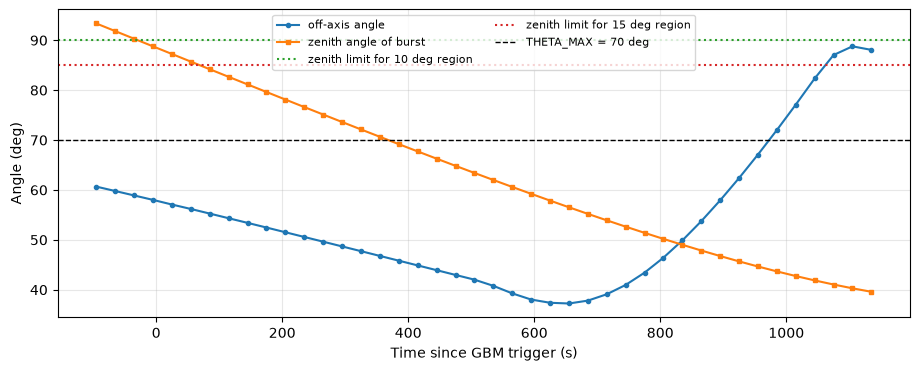

In [4]:
mid = 0.5 * (pointing.start + pointing.stop)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(mid, pointing.theta, 'o-', ms=3, label='off-axis angle')
ax.plot(mid, pointing.zenith, 's-', ms=3, label='zenith angle of burst')
for roi, c in ((ROI_EARLY, 'C2'), (ROI_FULL, 'C3')):
    ax.axhline(ZMAX - roi, color=c, ls=':', label=f'zenith limit for {roi:g} deg region')
ax.axhline(THETA_MAX, color='k', ls='--', lw=1, label=f'THETA_MAX = {THETA_MAX:g} deg')
ax.set_xlabel('Time since GBM trigger (s)')
ax.set_ylabel('Angle (deg)')
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=.3)
plt.show()

## 3. GBM episodes

The three NaI detectors with the largest excess are summed over 10–1000 keV. The background is a polynomial in rate fitted to windows on either side of the burst. The lowest order whose mean squared residual in those windows is at most `BKG_CHI2_MAX` is used; higher orders are listed because they can bulge across the burst and change the episodes.

Bayesian blocks run on the livetime-corrected rate. An episode is a run of consecutive blocks whose excess is at least `SIG_MIN` sigma, searched only between the background windows. The **initial period** is the first episode.

In [5]:
GBM_EBAND = (10., 1000.)      # keV
BKG_WINDOWS = [(-150., -15.), (420., 600.)]
BKG_CHI2_MAX = 1.2
SIG_MIN = 3.
P0 = 0.01
SEARCH = (BKG_WINDOWS[0][1], BKG_WINDOWS[1][0])

nai = ['n0', 'n1', 'n2', 'n3', 'n4', 'n5', 'n6', 'n7', 'n8', 'n9', 'na', 'nb']
gbm_files = {d: GBM_DIR / f'glg_ctime_{d}_{GBM_TRIGGER}_v00.pha' for d in nai}
rank = L.rank_gbm_detectors(gbm_files, T0, *GBM_EBAND, src_window=SEARCH, bkg_windows=BKG_WINDOWS)
display(rank.head(6).round(1))
GBM_DETS = list(rank.detector[:3])

lcs = [L.gbm_ctime_lightcurve(gbm_files[d], T0, *GBM_EBAND, -300., 1000.) for d in GBM_DETS]
lc = L.sum_lightcurves(lcs)

options = []
for order in (1, 2, 3):
    bkg = np.sum([L.fit_background(x, BKG_WINDOWS, order) for x in lcs], axis=0)
    blocks = L.gbm_blocks(lc, bkg, p0=P0)
    eps = L.episodes_from_blocks(blocks, SIG_MIN, search=SEARCH)
    options.append({'order': order, 'chi2_per_bin': L.background_chi2(lc, bkg, BKG_WINDOWS),
                    'episodes': [(round(a, 1), round(b, 1)) for a, b in zip(eps.t_lo, eps.t_hi)],
                    'bkg': bkg, 'blocks': blocks, 'eps': eps})
display(pd.DataFrame([{k: o[k] for k in ('order', 'chi2_per_bin', 'episodes')} for o in options]).round(3))

chosen = next(o for o in options if o['chi2_per_bin'] <= BKG_CHI2_MAX)
BKG_ORDER, gbm_bkg, blocks, episodes = chosen['order'], chosen['bkg'], chosen['blocks'], chosen['eps']
print(f'Detectors {GBM_DETS}; background order {BKG_ORDER}')
display(episodes.round(2))
EP1 = episodes.iloc[0]

,detector,net_counts,significance
0,n3,125724.7,201.4
1,n5,88993.7,162.3
2,n4,97611.8,159.9
3,n0,79324.2,142.6
4,n1,65191.2,119.6
5,n6,32016.2,52.9


,order,chi2_per_bin,episodes
0,1,1.228,"[(-8.2, 231.5), (303.1, 397.3)]"
1,2,1.201,"[(-8.2, 231.5), (331.8, 397.3)]"
2,3,1.198,"[(-8.2, 231.5), (331.8, 397.3)]"


Detectors ['n3', 'n5', 'n4']; background order 3


,t_lo,t_hi,n_blocks,peak_net_rate
0,-8.16,231.46,64,4049.17
1,331.81,397.34,15,4623.49


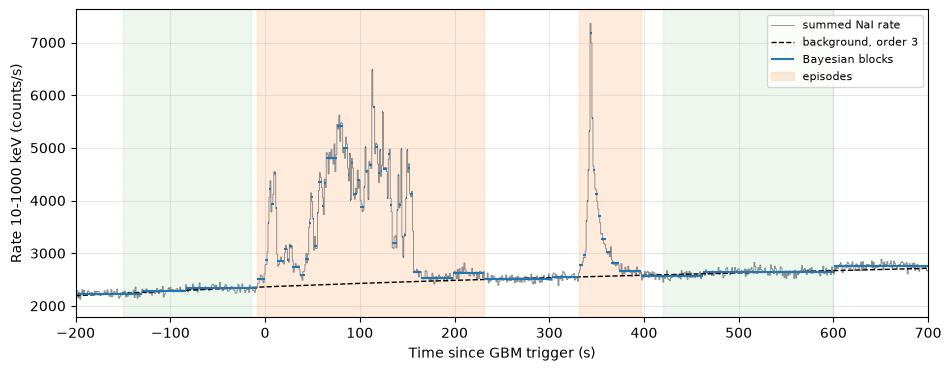

In [6]:
mid = 0.5 * (lc.t_lo + lc.t_hi)
rate = lc.counts / lc.livetime
fig, ax = plt.subplots(figsize=(11, 4))
ax.step(mid, rate, where='mid', lw=.6, color='0.5', label='summed NaI rate')
ax.plot(mid, gbm_bkg / lc.livetime, 'k--', lw=1, label=f'background, order {BKG_ORDER}')
bk_rate = np.interp(0.5 * (blocks.t_lo + blocks.t_hi), mid, gbm_bkg / lc.livetime)
ax.hlines(blocks.net_rate + bk_rate, blocks.t_lo, blocks.t_hi, color='C0', lw=1.5, label='Bayesian blocks')
for i, ep in episodes.iterrows():
    ax.axvspan(ep.t_lo, ep.t_hi, color='C1', alpha=.15, label='episodes' if i == 0 else None)
for a, b in BKG_WINDOWS:
    ax.axvspan(a, b, color='C2', alpha=.08)
ax.set_xlim(-200, 700)
ax.set_xlabel('Time since GBM trigger (s)')
ax.set_ylabel(f'Rate {GBM_EBAND[0]:g}-{GBM_EBAND[1]:g} keV (counts/s)')
ax.legend(fontsize=8)
ax.grid(alpha=.3)
plt.show()

## 4. Analysis windows

In [7]:
def gti_start_covering(gtis, t):
    for a, b in gtis:
        if b > t:
            return max(a, t)
    raise ValueError('no good time after', t)

A_START = gti_start_covering(gti_early, EP1.t_lo)
A_STOP = float(EP1.t_hi)
B_START = gti_full[0][0]
B_STOP = min(gti_full[-1][1], theta_exit)
COMMON = (B_START, A_STOP)
assert A_START < B_START < A_STOP < B_STOP

windows = pd.DataFrame([
    {'window': 'A: initial period', 'roi': ROI_EARLY, 'tmin': A_START, 'tmax': A_STOP,
     'set by': 'first GBM episode, 10 deg good time'},
    {'window': 'B: full LAT window', 'roi': ROI_FULL, 'tmin': B_START, 'tmax': B_STOP,
     'set by': f'15 deg good time, off-axis < {THETA_MAX:g} deg'},
    {'window': 'common interval', 'roi': np.nan, 'tmin': COMMON[0], 'tmax': COMMON[1],
     'set by': 'overlap of A and B'},
])
display(windows.round(2))

,window,roi,tmin,tmax,set by
0,A: initial period,10.0,-8.16,231.46,"first GBM episode, 10 deg good time"
1,B: full LAT window,15.0,70.04,972.81,"15 deg good time, off-axis < 70 deg"
2,common interval,NaN,70.04,231.46,overlap of A and B


## 5. LAT events

Raw counts are not fluxes; exposure changes with off-axis angle. The table lists every event above 1 GeV within 2° of the burst and the event classes it belongs to.

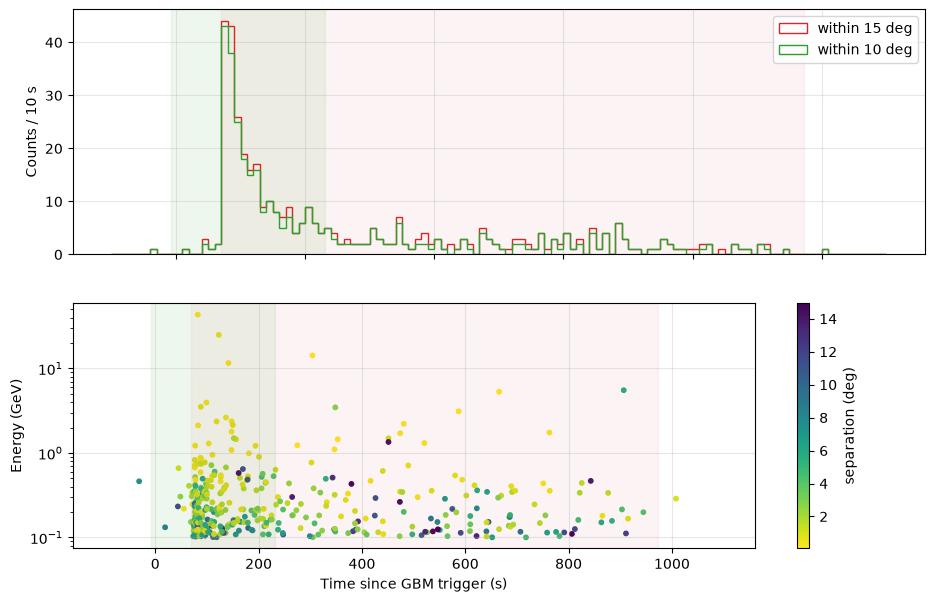

,t_rel,energy,sep,theta,zenith,TRANSIENT020E,TRANSIENT020,SOURCE
97,77.23,1220.23,0.33,55.10,83.64,1,1,1
112,82.24,43313.32,0.07,54.88,83.63,1,1,1
115,82.92,2121.21,0.15,54.73,83.62,1,1,1
126,88.12,3517.08,0.60,54.27,82.67,1,1,1
139,98.99,3951.56,0.29,54.34,82.98,1,1,1
146,103.41,1295.04,0.24,54.32,82.74,1,1,1
159,118.73,2357.60,0.57,53.78,81.29,1,1,1
162,122.92,24945.17,0.41,53.80,81.92,1,1,1
174,136.79,2628.47,0.24,52.90,80.76,1,1,1
177,141.64,11584.51,0.19,53.05,80.75,1,1,1


In [8]:
events = L.read_events(FT1, RA, DEC, T0)
in_class = (events.event_class & EVCLASS) != 0
basic = in_class & events.energy.between(EMIN, EMAX) & (events.zenith <= ZMAX)

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
edges = np.arange(-100, 1110, 10)
for roi, c in ((ROI_FULL, 'C3'), (ROI_EARLY, 'C2')):
    q = events[basic & (events.sep <= roi)]
    axes[0].hist(q.t_rel, bins=edges, histtype='step', color=c, label=f'within {roi:g} deg')
axes[0].set_ylabel('Counts / 10 s')
q = events[basic & (events.sep <= ROI_FULL)]
sc = axes[1].scatter(q.t_rel, q.energy / 1e3, c=q.sep, s=10, cmap='viridis_r')
plt.colorbar(sc, ax=axes[1], label='separation (deg)')
axes[1].set_yscale('log')
axes[1].set_ylabel('Energy (GeV)')
axes[1].set_xlabel('Time since GBM trigger (s)')
for ax in axes:
    ax.axvspan(A_START, A_STOP, color='C2', alpha=.08)
    ax.axvspan(B_START, B_STOP, color='C3', alpha=.05)
    ax.grid(alpha=.3)
axes[0].legend()
plt.show()

bright = events[(events.energy > 1000) & (events.sep < 2)].sort_values('t_rel').copy()
for bit, name in L.EVCLASS_NAME.items():
    bright[name] = ((bright.event_class & bit) != 0).astype(int)
display(bright[['t_rel', 'energy', 'sep', 'theta', 'zenith'] + list(L.EVCLASS_NAME.values())].round(2))

## 6. Analysis A: 10° region, initial period

Three fits: the whole initial period, the part before 15° good time starts (only this analysis covers it), and the common interval.

In [9]:
selA = selection(ROI_EARLY)
selA.write_model()
A_INTERVALS = {
    'A: initial period': (A_START, A_STOP),
    'A: before 15 deg good time': (A_START, B_START),
    'A: common interval': COMMON,
}
prepsA = dict(zip(A_INTERVALS, L.prepare_many([(selA, a, b) for a, b in A_INTERVALS.values()], WORKERS)))
rowsA = []
for name, prep in prepsA.items():
    row = L.fit_prepared(prep, ts_ul=TS_MIN, save_xml=prep.evfile.parent / 'fit.xml')
    row['approach'] = name
    rowsA.append(row)
resA = pd.DataFrame(rowsA)
show(resA)

approach,roi,evclass,tmin,tmax,exposed_s,n_events,ts,index,index_err,flux,flux_err,flux_ul95,eflux,eflux_err,npred,diffuse_at_bound,fit_code
A: initial period,10.000000,TRANSIENT020,-8.16,231.46,239.62,228,1315.82,-2.22,0.07,0.000292,1.98e-05,,2.04e-07,2.79e-08,227.88,"GalDiffuse,IsoDiffuse",0
A: before 15 deg good time,10.000000,TRANSIENT020,-8.16,70.04,78.20,6,18.01,-2.16,0.48,2.31e-05,1.12e-05,4.29e-05,1.8e-08,1.68e-08,5.31,GalDiffuse,0
A: common interval,10.000000,TRANSIENT020,70.04,231.46,161.42,222,1410.74,-2.21,0.07,0.0004,2.74e-05,,2.83e-07,3.97e-08,221.95,"GalDiffuse,IsoDiffuse",0


## 7. Analysis B: 15° region, full LAT window

The window is first cut at every GBM episode edge inside it. Each piece is then split at the median arrival time of events within `R_CORE` of the burst, and the split is kept only if both halves have a test statistic of at least `TS_MIN`. Pieces that cannot be split stay as single bins; a bin below `TS_MIN` gets a 95% upper limit with the index fixed at −2.

In [10]:
selB = selection(ROI_FULL)
selB.write_model()
cuts = sorted({float(t) for ep in episodes.itertuples() for t in (ep.t_lo, ep.t_hi) if B_START < t < B_STOP})
edges_B = [B_START] + cuts + [B_STOP]
segments = list(zip(edges_B[:-1], edges_B[1:]))
print('Segments:', [(round(a, 2), round(b, 2)) for a, b in segments])

bins_B, resB = L.adaptive_bins(selB, segments, events, ts_min=TS_MIN, r_core=R_CORE, workers=WORKERS)
resB['approach'] = 'B: bin'
show(resB)

Segments: [(70.04, 231.46), (231.46, 331.81), (331.81, 397.34), (397.34, 972.81)]
split 70.04-231.46 at 105.47: TS 897.9 / 643.9
split 231.46-331.81 at 281.60: TS 69.4 / 61.8
split 331.81-397.34 at 356.36: TS 51.2 / 33.0
split 397.34-972.81 at 609.87: TS 171.6 / 149.3
split 70.04-105.47 at 82.79: TS 489.7 / 419.6
split 105.47-231.46 at 141.64: TS 349.7 / 315.9
split 231.46-281.60 at 258.86: TS 38.7 / 27.0
split 397.34-609.87 at 480.95: TS 84.2 / 89.3
split 609.87-972.81 at 692.94: TS 74.0 / 75.5
split 82.79-105.47 at 91.56: TS 226.2 / 195.9
split 105.47-141.64 at 125.08: TS 179.9 / 170.1
split 141.64-231.46 at 171.60: TS 167.4 / 154.6
split 397.34-480.95 at 441.21: TS 37.8 / 49.2
split 480.95-609.87 at 563.43: TS 38.0 / 53.7
split 609.87-692.94 at 669.54: TS 38.0 / 38.5
split 692.94-972.81 at 763.21: TS 47.8 / 31.0
split 91.56-105.47 at 98.58: TS 93.8 / 103.2
split 105.47-125.08 at 110.59: TS 79.6 / 103.8
split 141.64-171.60 at 151.85: TS 112.0 / 59.8
split 171.60-231.46 at 200.39: TS 

approach,roi,evclass,tmin,tmax,exposed_s,n_events,ts,index,index_err,flux,flux_err,flux_ul95,eflux,eflux_err,npred,diffuse_at_bound,fit_code
B: bin,15.000000,TRANSIENT020,70.04,82.79,12.75,61,489.68,-2.43,0.17,0.00153,0.0002,,7.7e-07,1.73e-07,60.98,"GalDiffuse,IsoDiffuse",0
B: bin,15.000000,TRANSIENT020,82.79,91.56,8.77,29,226.19,-2.22,0.21,0.00103,0.000194,,7.1e-07,2.75e-07,29.02,"GalDiffuse,IsoDiffuse",0
B: bin,15.000000,TRANSIENT020,91.56,98.58,7.02,17,93.77,-2.39,0.33,0.000706,0.000189,,3.76e-07,1.76e-07,15.57,IsoDiffuse,0
B: bin,15.000000,TRANSIENT020,98.58,105.47,6.89,15,103.21,-2.14,0.27,0.00062,0.000163,,5.06e-07,2.92e-07,14.99,"GalDiffuse,IsoDiffuse",0
B: bin,15.000000,TRANSIENT020,105.47,110.59,5.12,12,79.60,-2.39,0.36,0.000676,0.000199,,3.62e-07,1.91e-07,11.92,IsoDiffuse,0
B: bin,15.000000,TRANSIENT020,110.59,125.08,14.49,18,103.77,-2.02,0.23,0.00034,8.15e-05,,3.56e-07,1.99e-07,17.98,"GalDiffuse,IsoDiffuse",0
B: bin,15.000000,TRANSIENT020,125.08,141.64,16.56,24,170.13,-2.30,0.25,0.000414,8.59e-05,,2.51e-07,1.01e-07,23.99,"GalDiffuse,IsoDiffuse",0
B: bin,15.000000,TRANSIENT020,141.64,151.85,10.21,11,112.04,-1.63,0.21,0.00027,8.27e-05,,8.97e-07,6.4e-07,10.99,"GalDiffuse,IsoDiffuse",0
B: bin,15.000000,TRANSIENT020,151.85,163.79,11.94,8,32.09,-1.94,0.38,0.000146,6.35e-05,,1.9e-07,1.86e-07,6.52,,0
B: bin,15.000000,TRANSIENT020,163.79,171.60,7.81,6,27.94,-2.21,0.52,0.000172,8.38e-05,,1.22e-07,1.21e-07,4.77,GalDiffuse,0


In [11]:
B_INTERVALS = {'B: full LAT window': (B_START, B_STOP), 'B: common interval': COMMON}
prepsB = dict(zip(B_INTERVALS, L.prepare_many([(selB, a, b) for a, b in B_INTERVALS.values()], WORKERS)))
rowsB = []
for name, prep in prepsB.items():
    row = L.fit_prepared(prep, ts_ul=TS_MIN, save_xml=prep.evfile.parent / 'fit.xml')
    row['approach'] = name
    rowsB.append(row)
resB_whole = pd.DataFrame(rowsB)
show(resB_whole)

approach,roi,evclass,tmin,tmax,exposed_s,n_events,ts,index,index_err,flux,flux_err,flux_ul95,eflux,eflux_err,npred,diffuse_at_bound,fit_code
B: full LAT window,15.000000,TRANSIENT020,70.04,972.81,902.77,385,1515.24,-2.21,0.06,9.17e-05,5.43e-06,,6.49e-08,7.62e-09,345.76,,156
B: common interval,15.000000,TRANSIENT020,70.04,231.46,161.42,237,1423.64,-2.21,0.08,0.000398,2.78e-05,,2.81e-07,3.96e-08,229.46,GalDiffuse,0


## 8. Comparing the two analyses on the common interval

The 15° sample contains every event of the 10° sample, so the two fits are not independent. Two estimates of the significance of the index difference are given: `naive` treats them as independent and understates the significance; `nested` uses \(\sqrt{|\sigma_A^2-\sigma_B^2|}\), which is appropriate when one sample contains the other.

The same interval is also fitted in `TRANSIENT020E` and `SOURCE` for both regions.

In [12]:
class_jobs = [(selection(roi, cls), *COMMON) for roi in (ROI_EARLY, ROI_FULL) for cls in (8, 128)]
for sel, *_ in class_jobs:
    sel.write_model()
class_rows = []
for prep in L.prepare_many(class_jobs, WORKERS):
    row = L.fit_prepared(prep, ts_ul=TS_MIN)
    row['approach'] = f'{prep.sel.roi:g} deg common interval'
    class_rows.append(row)

common = pd.concat([resA[resA.approach == 'A: common interval'],
                    resB_whole[resB_whole.approach == 'B: common interval'],
                    pd.DataFrame(class_rows)], ignore_index=True)
show(common.sort_values(['evclass', 'roi']))

cmp_rows = []
for cls, g in common.groupby('evclass'):
    a, b = g[g.roi == ROI_EARLY].iloc[0], g[g.roi == ROI_FULL].iloc[0]
    d = a['index'] - b['index']
    cmp_rows.append({'evclass': cls, 'index_10deg': a['index'], 'index_15deg': b['index'],
                     'difference': d,
                     'naive_sigma': d / np.hypot(a.index_err, b.index_err),
                     'nested_sigma': d / np.sqrt(abs(a.index_err ** 2 - b.index_err ** 2)),
                     'flux_ratio_10_over_15': a.flux / b.flux})
display(pd.DataFrame(cmp_rows).round(3))

approach,roi,evclass,tmin,tmax,exposed_s,n_events,ts,index,index_err,flux,flux_err,flux_ul95,eflux,eflux_err,npred,diffuse_at_bound,fit_code
10 deg common interval,10.000000,SOURCE,70.04,231.46,161.42,144,1128.05,-2.16,0.08,0.000381,3.38e-05,,2.97e-07,4.68e-08,143.96,"GalDiffuse,IsoDiffuse",0
15 deg common interval,15.000000,SOURCE,70.04,231.46,161.42,146,1139.27,-2.15,0.08,0.000377,3.31e-05,,2.97e-07,4.7e-08,145.93,"GalDiffuse,IsoDiffuse",0
A: common interval,10.000000,TRANSIENT020,70.04,231.46,161.42,222,1410.74,-2.21,0.07,0.0004,2.74e-05,,2.83e-07,3.97e-08,221.95,"GalDiffuse,IsoDiffuse",0
B: common interval,15.000000,TRANSIENT020,70.04,231.46,161.42,237,1423.64,-2.21,0.08,0.000398,2.78e-05,,2.81e-07,3.96e-08,229.46,GalDiffuse,0
10 deg common interval,10.000000,TRANSIENT020E,70.04,231.46,161.42,236,1510.21,-2.21,0.07,0.000405,2.68e-05,,2.88e-07,3.98e-08,235.92,"GalDiffuse,IsoDiffuse",0
15 deg common interval,15.000000,TRANSIENT020E,70.04,231.46,161.42,251,1523.37,-2.21,0.08,0.000404,2.86e-05,,2.86e-07,4e-08,244.51,,156


,evclass,index_10deg,index_15deg,difference,naive_sigma,nested_sigma,flux_ratio_10_over_15
0,SOURCE,-2.157,-2.154,-0.003,-0.029,-0.357,1.009
1,TRANSIENT020,-2.210,-2.210,0.001,0.007,0.128,1.005
2,TRANSIENT020E,-2.208,-2.208,0.001,0.006,0.028,1.003


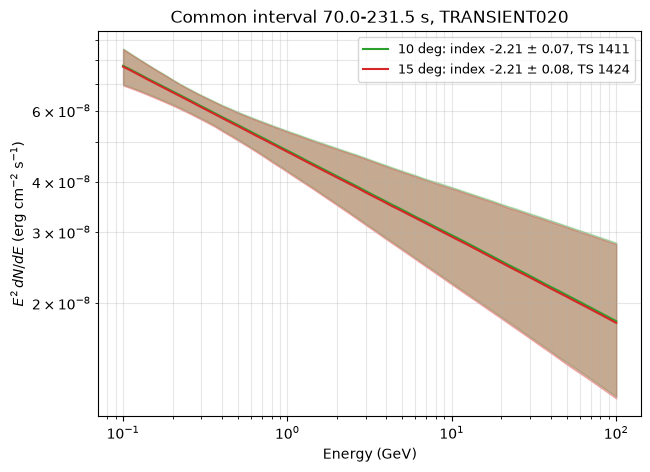

In [13]:
energies = np.logspace(np.log10(EMIN), np.log10(EMAX), 60)
fig, ax = plt.subplots(figsize=(7, 5))
for name, color in (('A: common interval', 'C2'), ('B: common interval', 'C3')):
    r = common[(common.approach == name)].iloc[0]
    med, lo, hi = L.powerlaw2_band(r.flux, r.flux_err, r['index'], r.index_err, r.corr_flux_index,
                                   EMIN, EMAX, energies)
    ax.fill_between(energies / 1e3, lo, hi, color=color, alpha=.3)
    ax.plot(energies / 1e3, med, color=color,
            label=f"{r.roi:g} deg: index {r['index']:.2f} ± {r.index_err:.2f}, TS {r.ts:.0f}")
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Energy (GeV)')
ax.set_ylabel(r'$E^2\,dN/dE$ (erg cm$^{-2}$ s$^{-1}$)')
ax.set_title(f'Common interval {COMMON[0]:.1f}-{COMMON[1]:.1f} s, TRANSIENT020')
ax.legend(fontsize=9)
ax.grid(alpha=.3, which='both')
plt.show()

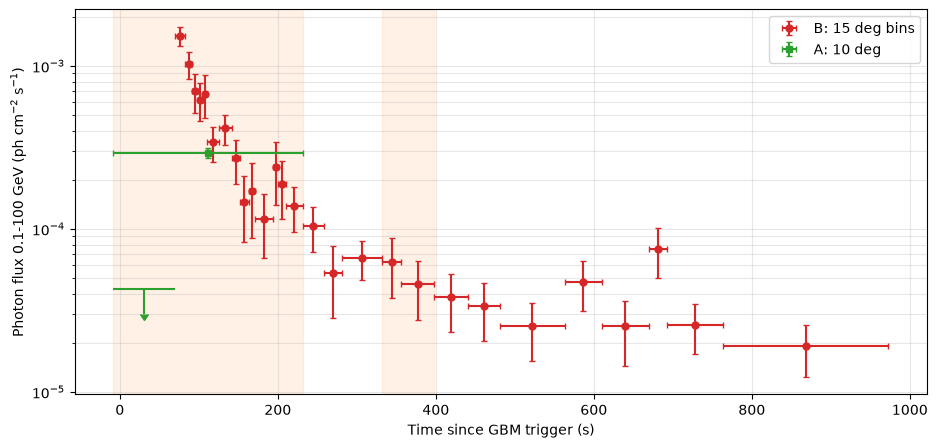

In [14]:
def plot_fluxes(ax, df, color, label, marker='o'):
    det = df[df.ts >= TS_MIN]
    t_mid = 0.5 * (det.tmin + det.tmax)
    ax.errorbar(t_mid, det.flux, xerr=[t_mid - det.tmin, det.tmax - t_mid], yerr=det.flux_err,
                fmt=marker, color=color, ms=5, capsize=2, label=label)
    ul = df[(df.ts < TS_MIN) & df.flux_ul95.notna()]
    if len(ul):
        t_mid = 0.5 * (ul.tmin + ul.tmax)
        ax.errorbar(t_mid, ul.flux_ul95, xerr=[t_mid - ul.tmin, ul.tmax - t_mid], yerr=0.3 * ul.flux_ul95,
                    uplims=True, fmt='none', color=color)

fig, ax = plt.subplots(figsize=(11, 5))
plot_fluxes(ax, resB, 'C3', f'B: {ROI_FULL:g} deg bins')
plot_fluxes(ax, resA[resA.approach != 'A: common interval'], 'C2', f'A: {ROI_EARLY:g} deg', marker='s')
for _, ep in episodes.iterrows():
    ax.axvspan(ep.t_lo, ep.t_hi, color='C1', alpha=.1)
ax.set_yscale('log')
ax.set_xlabel('Time since GBM trigger (s)')
ax.set_ylabel(f'Photon flux {EMIN / 1e3:g}-{EMAX / 1e3:g} GeV (ph cm$^{{-2}}$ s$^{{-1}}$)')
ax.legend()
ax.grid(alpha=.3, which='both')
plt.show()

## 9. SOURCE-class cross-check of the 15° bins

Same bins, refitted with `evclass=128` and `P8R3_SOURCE_V3`. `SOURCE` has less background and fewer photons, so a transient-class artefact would show up as a large change in flux or index.

In [15]:
selB_src = selection(ROI_FULL, 128)
selB_src.write_model()
src_rows = []
for prep in L.prepare_many([(selB_src, a, b) for a, b in bins_B], WORKERS):
    row = L.fit_prepared(prep, ts_ul=TS_MIN)
    row['approach'] = 'B: bin, SOURCE'
    src_rows.append(row)
resB_src = pd.DataFrame(src_rows)
show(resB_src)

pair = resB[['tmin', 'tmax', 'ts', 'index', 'index_err', 'flux', 'flux_err']].merge(
    resB_src[['tmin', 'tmax', 'ts', 'index', 'index_err', 'flux', 'flux_err']],
    on=['tmin', 'tmax'], suffixes=('_t020', '_source'))
pair['flux_ratio'] = pair.flux_source / pair.flux_t020
pair['index_diff_sigma'] = (pair.index_source - pair.index_t020) / np.hypot(pair.index_err_source, pair.index_err_t020)
display(pair.round(3))

approach,roi,evclass,tmin,tmax,exposed_s,n_events,ts,index,index_err,flux,flux_err,flux_ul95,eflux,eflux_err,npred,diffuse_at_bound,fit_code
"B: bin, SOURCE",15.000000,SOURCE,70.04,82.79,12.75,32,325.24,-2.32,0.20,0.00125,0.000234,,7.3e-07,2.13e-07,32.01,"GalDiffuse,IsoDiffuse",0
"B: bin, SOURCE",15.000000,SOURCE,82.79,91.56,8.77,22,212.11,-2.21,0.22,0.00119,0.000271,,8.51e-07,3.3e-07,21.95,GalDiffuse,0
"B: bin, SOURCE",15.000000,SOURCE,91.56,98.58,7.02,13,83.38,-2.57,0.38,0.000923,0.00029,,3.98e-07,1.57e-07,12.12,"GalDiffuse,IsoDiffuse",0
"B: bin, SOURCE",15.000000,SOURCE,98.58,105.47,6.89,10,90.45,-2.02,0.29,0.000589,0.000198,,6.25e-07,4.1e-07,9.92,"GalDiffuse,IsoDiffuse",0
"B: bin, SOURCE",15.000000,SOURCE,105.47,110.59,5.12,9,78.98,-2.65,0.45,0.00086,0.000302,,3.45e-07,1.49e-07,9.00,"GalDiffuse,IsoDiffuse",0
"B: bin, SOURCE",15.000000,SOURCE,110.59,125.08,14.49,9,64.16,-1.75,0.29,0.000213,9.47e-05,,4.78e-07,3.66e-07,8.64,GalDiffuse,0
"B: bin, SOURCE",15.000000,SOURCE,125.08,141.64,16.56,15,140.37,-2.20,0.27,0.000387,0.000106,,2.78e-07,1.33e-07,14.99,"GalDiffuse,IsoDiffuse",0
"B: bin, SOURCE",15.000000,SOURCE,141.64,151.85,10.21,8,103.15,-1.53,0.23,0.000249,9.29e-05,,1.14e-06,8.28e-07,7.99,"GalDiffuse,IsoDiffuse",0
"B: bin, SOURCE",15.000000,SOURCE,151.85,163.79,11.94,3,21.69,-1.85,0.46,9.38e-05,5.75e-05,0.000226,1.55e-07,1.95e-07,3.01,"GalDiffuse,IsoDiffuse",0
"B: bin, SOURCE",15.000000,SOURCE,163.79,171.60,7.81,3,19.91,-2.59,0.76,0.000181,0.000111,0.000345,7.7e-08,6.03e-08,2.97,"GalDiffuse,IsoDiffuse",0


,tmin,tmax,ts_t020,index_t020,index_err_t020,flux_t020,flux_err_t020,ts_source,index_source,index_err_source,flux_source,flux_err_source,flux_ratio,index_diff_sigma
0,70.038,82.790,489.681,-2.435,0.168,0.002,0.0,325.244,-2.323,0.196,0.001,0.0,0.813,0.434
1,82.790,91.560,226.194,-2.222,0.210,0.001,0.0,212.109,-2.205,0.219,0.001,0.0,1.162,0.056
2,91.560,98.580,93.765,-2.390,0.328,0.001,0.0,83.375,-2.574,0.380,0.001,0.0,1.307,-0.367
3,98.580,105.470,103.211,-2.135,0.275,0.001,0.0,90.450,-2.018,0.286,0.001,0.0,0.951,0.297
4,105.470,110.590,79.595,-2.387,0.365,0.001,0.0,78.975,-2.654,0.455,0.001,0.0,1.272,-0.458
5,110.590,125.080,103.773,-2.023,0.230,0.000,0.0,64.164,-1.748,0.288,0.000,0.0,0.625,0.748
6,125.080,141.640,170.127,-2.301,0.245,0.000,0.0,140.372,-2.201,0.265,0.000,0.0,0.934,0.277
7,141.640,151.850,112.042,-1.627,0.212,0.000,0.0,103.146,-1.530,0.225,0.000,0.0,0.919,0.314
8,151.850,163.790,32.094,-1.937,0.378,0.000,0.0,21.686,-1.851,0.461,0.000,0.0,0.641,0.144
9,163.790,171.600,27.940,-2.205,0.522,0.000,0.0,19.914,-2.591,0.761,0.000,0.0,1.058,-0.418


## 10. Decay after the last GBM episode

A power law \(F \propto t^{-\alpha}\) fitted to the 15° bins that start after the last GBM episode ends, using the geometric mid-time of each bin. Bins below `TS_MIN` are left out.

In [16]:
LAST_EP_END = float(episodes.t_hi.max())
late = resB[(resB.tmin >= LAST_EP_END) & (resB.ts >= TS_MIN)]
if len(late) >= 3:
    t = np.sqrt(late.tmin * late.tmax)
    y = np.log10(late.flux)
    sy = late.flux_err / late.flux / np.log(10)
    coef, cov = np.polyfit(np.log10(t), y, 1, w=1 / sy, cov='unscaled')
    print(f'alpha = {-coef[0]:.2f} ± {np.sqrt(cov[0, 0]):.2f} from {len(late)} bins after {LAST_EP_END:.1f} s')
else:
    print(f'Only {len(late)} detected bins after {LAST_EP_END:.1f} s; no decay fit')

alpha = 0.46 ± 0.58 from 8 bins after 397.3 s


## 11. High-energy photons

`gtsrcprob` uses the fitted model of each whole-window fit. Probabilities depend on the model, so the two columns are separate measurements, each for its own region and interval.

In [17]:
probs = []
for name, prep in (('A', prepsA['A: initial period']), ('B', prepsB['B: full LAT window'])):
    df = L.source_probabilities(prep, prep.evfile.parent / 'fit.xml', prep.evfile.parent / 'probs.fits', RA, DEC)
    probs.append(df[['run_id', 'event_id', 't_rel', 'energy', 'sep', 'theta', 'p_grb']].rename(columns={'p_grb': f'p_grb_{name}'}))
hep = probs[0].merge(probs[1], on=['run_id', 'event_id', 't_rel', 'energy', 'sep', 'theta'], how='outer')
hep = hep[hep.energy > 1000].sort_values('energy', ascending=False)
hep['source_frame_GeV'] = hep.energy * (1 + Z) / 1e3
display(hep.head(15).round(4))

,run_id,event_id,t_rel,energy,sep,theta,p_grb_A,p_grb_B,source_frame_GeV
62,811902605,6318426,82.2351,43313.3242,0.0700,54.8840,1.0,1.0000,195.3431
156,811902605,6395683,122.9167,24945.1738,0.4144,53.7952,1.0,0.9986,112.5027
264,811902605,6733011,304.1470,14236.3711,0.0751,47.9092,NaN,1.0000,64.2060
182,811902605,6430820,141.6406,11584.5068,0.1868,53.0536,1.0,1.0000,52.2461
387,811902605,7948359,906.7330,5528.4185,5.6531,56.5227,NaN,0.0501,24.9332
353,811902605,7429618,665.5531,5296.5381,0.0565,37.6882,NaN,1.0000,23.8874
113,811902605,6350218,98.9878,3951.5610,0.2882,54.3353,1.0,0.9999,17.8215
84,811902605,6329532,88.1172,3517.0759,0.6029,54.2692,1.0,0.9993,15.8620
281,811902605,6816336,348.4244,3464.1470,2.8138,45.3596,NaN,0.6678,15.6233
334,811902605,7274424,587.1671,3110.5571,0.1170,37.8719,NaN,1.0000,14.0286


In [18]:
all_rows = pd.concat([resA, resB, resB_whole, pd.DataFrame(class_rows), resB_src], ignore_index=True)
all_rows.to_csv(RESULTS / 'lat_fits.csv', index=False)
episodes.to_csv(RESULTS / 'gbm_episodes.csv', index=False)
windows.to_csv(RESULTS / 'analysis_windows.csv', index=False)
hep.to_csv(RESULTS / 'high_energy_photons.csv', index=False)
print('Saved to', RESULTS)

Saved to /home/growth/sameer/grb_investigation/results/GRB260924A


## 12. Caveats

- The GBM episode boundaries depend on the background model; the table in section 3 shows how they move with polynomial order.
- Galactic diffuse and isotropic normalizations are free in each fit within [0, 10]. In short intervals the Galactic normalization often sits at a bound; `diffuse_at_bound` flags this.
- 4FGL-DR4 sources are fixed at catalog values. Over a few hundred seconds they contribute almost no photons.
- Energy dispersion is not modelled. Below about 300 MeV this biases the spectrum slightly.
- The burst is 37–58° off-axis during the bright LAT emission. Reconstructed energies and effective area are less certain there, especially for the highest-energy photons.
- A Lorentz-factor limit from the highest-energy photon also needs the target photon field, variability time, and geometry; it is not derived here.